# Step 3: PH dimension and generalization of fcn-5 on MNIST

Re-implementation of Birdal, Lou, Guibas, Şimşekli, *Intrinsic Dimension, Persistent Homology and Generalization in Neural Networks* (NeurIPS 2021), experiments with trained networks. The estimator and the training loop come from the `phdim` package (`phdim/estimator.py`, `phdim/training.py`); the validation of the estimator (sets of known dimension, Lévy paths) is in `validation.ipynb`.

Runs on a Colab GPU server. To connect: click inside a cell, then **Ctrl+Shift+P → Notebook: Select Notebook Kernel → Select Another Kernel → Colab → New Colab Server → GPU → T4**. Save after running cells so the outputs are kept in the file.

## Setup

In [1]:
!nvidia-smi

Wed Oct 28 07:31:01 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os

if os.path.basename(os.getcwd()) in ("drafts", "notebooks", "experiments"):  # running inside a local clone
    %cd ..
if not os.path.isdir("phdim"):  # on Colab: fetch the repository
    !git clone -q https://github.com/mahird3/phdim-generalization.git
    %cd phdim-generalization
%pip install -q -e .

In [ ]:
import pickle
import time

import numpy as np
import torch
import matplotlib.pyplot as plt

from phdim import distance_matrix, ph_dim
from phdim.training import fcn, load_mnist, train_run

device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device", device)

## Trajectories of real networks

fcn-5 on MNIST (as in the official code: 5 linear layers of width 100, no bias, ReLU), plain SGD (no momentum, no weight decay), learning rate × batch size grid.

For each run (`train_run`):
1. train until 100% training accuracy (checked every 100 steps);
2. run 200 more SGD steps, saving the flattened weights after each one;
3. `distance_matrix` of those 200 iterates (computed on the GPU, since the trajectory is a GPU tensor), then `ph_dim`;
4. generalization gap = train accuracy − test accuracy.

Then Kendall τ between dimension and gap (Fig. 2), and the distance matrices sorted by dimension (Fig. 4).

In [ ]:
train, test = load_mnist(device)
print("train", tuple(train[0].shape), "test", tuple(test[0].shape),
      "| fcn-5 parameters:", sum(p.numel() for p in fcn().parameters()))

# One trial run: timing, and the distance matrix computed on the GPU must equal the one computed on the CPU
trial = train_run(train, test, lr=0.1, batch_size=100, keep_traj=True)
print(f"trial: {trial['iters']} steps to 100% train acc, {trial['seconds']:.0f} s, "
      f"test acc {trial['test_acc']:.2f}%, gap {trial['gap']:.2f}")
D_cpu = distance_matrix(trial["traj"].cpu().numpy())
same_D = np.allclose(trial["D"], D_cpu, rtol=1e-9, atol=1e-12)
print("distance matrix GPU == CPU:", "OK" if same_D else "FAIL")
print(f"trial dimension: {ph_dim(D=trial['D'], n_repeats=5):.3f}")
del trial["traj"]
assert same_D

### The grid

6 learning rates × 2 batch sizes (the two columns of Fig. 2). Each run keeps only its 200 × 200 distance matrix, so any α or estimator setting can be recomputed later without retraining. Results are also saved to `results/step3_fcn5_mnist.pkl` on the server.

In [ ]:
import os

lrs = [0.01, 0.02, 0.04, 0.06, 0.08, 0.1]
batch_sizes = [50, 100]

runs, t0 = [], time.time()
for b in batch_sizes:
    for lr in lrs:
        r = train_run(train, test, lr, b)
        runs.append(r)
        if r["diverged"]:
            print(f"lr {lr:<5} b {b:<4} diverged after {r['iters']} steps")
            continue
        print(f"lr {lr:<5} b {b:<4} steps {r['iters']:>6}{'' if r['converged'] else ' (not 100%)'}   "
              f"train {r['train_acc']:6.2f}   test {r['test_acc']:5.2f}   gap {r['gap']:5.2f}   {r['seconds']:4.0f} s")
print(f"total {(time.time() - t0) / 60:.1f} min")

os.makedirs("results", exist_ok=True)
with open("results/step3_fcn5_mnist.pkl", "wb") as f:
    pickle.dump(runs, f)

lr 0.01  b 50   steps  58600   train 100.00   test 97.85   gap  2.15     86 s
lr 0.02  b 50   steps  43200   train 100.00   test 97.99   gap  2.01     63 s
lr 0.04  b 50   steps  30300   train 100.00   test 98.19   gap  1.81     45 s
lr 0.06  b 50   steps  31200   train 100.00   test 98.17   gap  1.83     46 s
lr 0.08  b 50   steps  29900   train 100.00   test 98.27   gap  1.73     43 s
lr 0.1   b 50   steps  47900   train 100.00   test 98.14   gap  1.86     70 s
lr 0.01  b 100  steps  53200   train 100.00   test 97.67   gap  2.33     77 s
lr 0.02  b 100  steps  28800   train 100.00   test 97.89   gap  2.11     43 s
lr 0.04  b 100  steps  18800   train 100.00   test 97.99   gap  2.01     28 s
lr 0.06  b 100  steps  15600   train 100.00   test 97.98   gap  2.02     23 s
lr 0.08  b 100  steps  16800   train 100.00   test 98.02   gap  1.98     25 s
lr 0.1   b 100  steps  15600   train 100.00   test 98.18   gap  1.82     23 s
total 9.6 min


### Fig. 2: dimension vs generalization

`ph_dim` on each saved distance matrix (α = 1, 5 random subsets per size), then Kendall τ between dimension and gap, over all runs and per batch size. The paper predicts τ > 0: higher dimension, larger gap, lower test accuracy.

  lr    b    dim    gap   test acc
0.04  50   1.373   1.81   98.19
0.08  50   1.482   1.73   98.27
0.1   50   1.510   1.86   98.14
0.06  50   1.633   1.83   98.17
0.1   100  1.718   1.82   98.18
0.08  100  1.836   1.98   98.02
0.01  50   1.840   2.15   97.85
0.02  50   1.866   2.01   97.99
0.06  100  1.910   2.02   97.98
0.04  100  2.061   2.01   97.99
0.02  100  2.105   2.11   97.89
0.01  100  2.183   2.33   97.67

Kendall tau(dim, gap), all runs: +0.697   (p = 0.001)
  batch size 50: +0.600
  batch size 100: +0.867
tau(dim, lr/b) = -0.698   tau(gap, lr/b) = -0.698


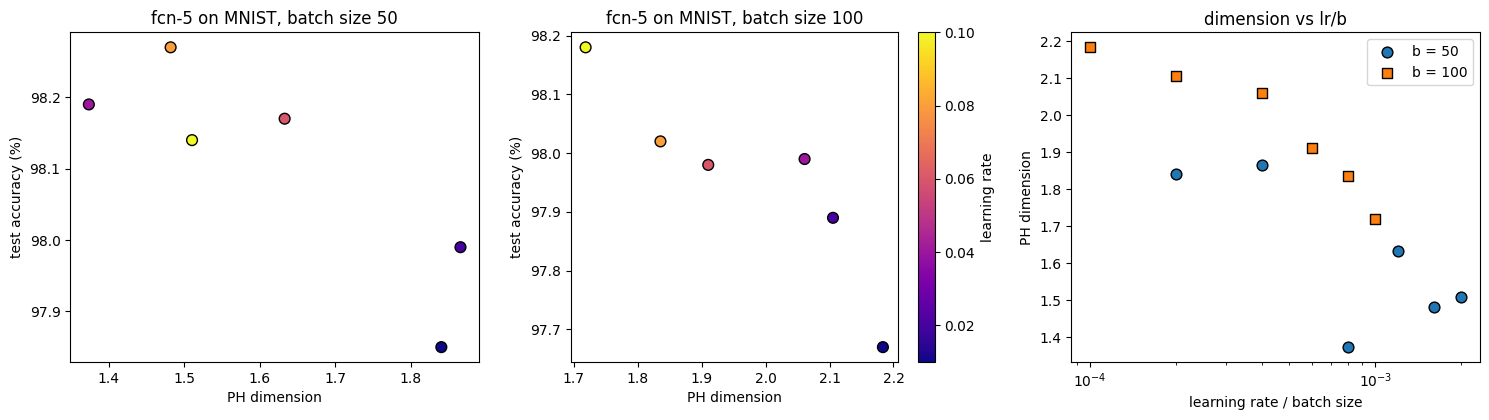

In [13]:
from scipy.stats import kendalltau

ok = [r for r in runs if not r["diverged"]]
for r in ok:
    r["dim"], r["curve"] = ph_dim(D=r["D"], n_repeats=5, return_curve=True)

print("  lr    b    dim    gap   test acc")
for r in sorted(ok, key=lambda r: r["dim"]):
    print(f"{r['lr']:<5} {r['batch_size']:<4} {r['dim']:.3f}  {r['gap']:5.2f}   {r['test_acc']:.2f}")

def tau(rs, x, y):
    return kendalltau([r[x] for r in rs], [r[y] for r in rs])

t_all = tau(ok, "dim", "gap")
print(f"\nKendall tau(dim, gap), all runs: {t_all.statistic:+.3f}   (p = {t_all.pvalue:.3f})")
for b in batch_sizes:
    t = tau([r for r in ok if r["batch_size"] == b], "dim", "gap")
    print(f"  batch size {b}: {t.statistic:+.3f}")

# Both dim and gap may simply follow lr/b; these two numbers show how much of the link goes through it
for r in ok:
    r["lr_over_b"] = r["lr"] / r["batch_size"]
print(f"tau(dim, lr/b) = {tau(ok, 'dim', 'lr_over_b').statistic:+.3f}   "
      f"tau(gap, lr/b) = {tau(ok, 'gap', 'lr_over_b').statistic:+.3f}")
if min(r["dim"] for r in ok) < 1.2:
    print("warning: some dimensions are close to alpha = 1, where the estimate saturates (step 2)")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
cmap = plt.cm.plasma
for ax, b in zip(axes[:2], batch_sizes):
    rs = [r for r in ok if r["batch_size"] == b]
    sc = ax.scatter([r["dim"] for r in rs], [r["test_acc"] for r in rs], c=[r["lr"] for r in rs],
                    cmap=cmap, vmin=min(lrs), vmax=max(lrs), s=60, edgecolor="k")
    ax.set_xlabel("PH dimension")
    ax.set_ylabel("test accuracy (%)")
    ax.set_title(f"fcn-5 on MNIST, batch size {b}")
fig.colorbar(sc, ax=axes[1], label="learning rate")
ax = axes[2]
for b, mk in zip(batch_sizes, "os"):
    rs = [r for r in ok if r["batch_size"] == b]
    ax.scatter([r["lr_over_b"] for r in rs], [r["dim"] for r in rs], marker=mk, s=60, edgecolor="k", label=f"b = {b}")
ax.set_xscale("log")
ax.set_xlabel("learning rate / batch size")
ax.set_ylabel("PH dimension")
ax.set_title("dimension vs lr/b")
ax.legend()
plt.tight_layout()
plt.show()

### Fig. 4: what the dimension sees

Four runs sorted by dimension (lowest to highest). Top: the 200 × 200 distance matrix of the iterates. Bottom: log E₁(k) vs log k with the fitted line. The paper reports that low-dimension runs show blocky matrices (clusters separated by jumps) and flatter lines.

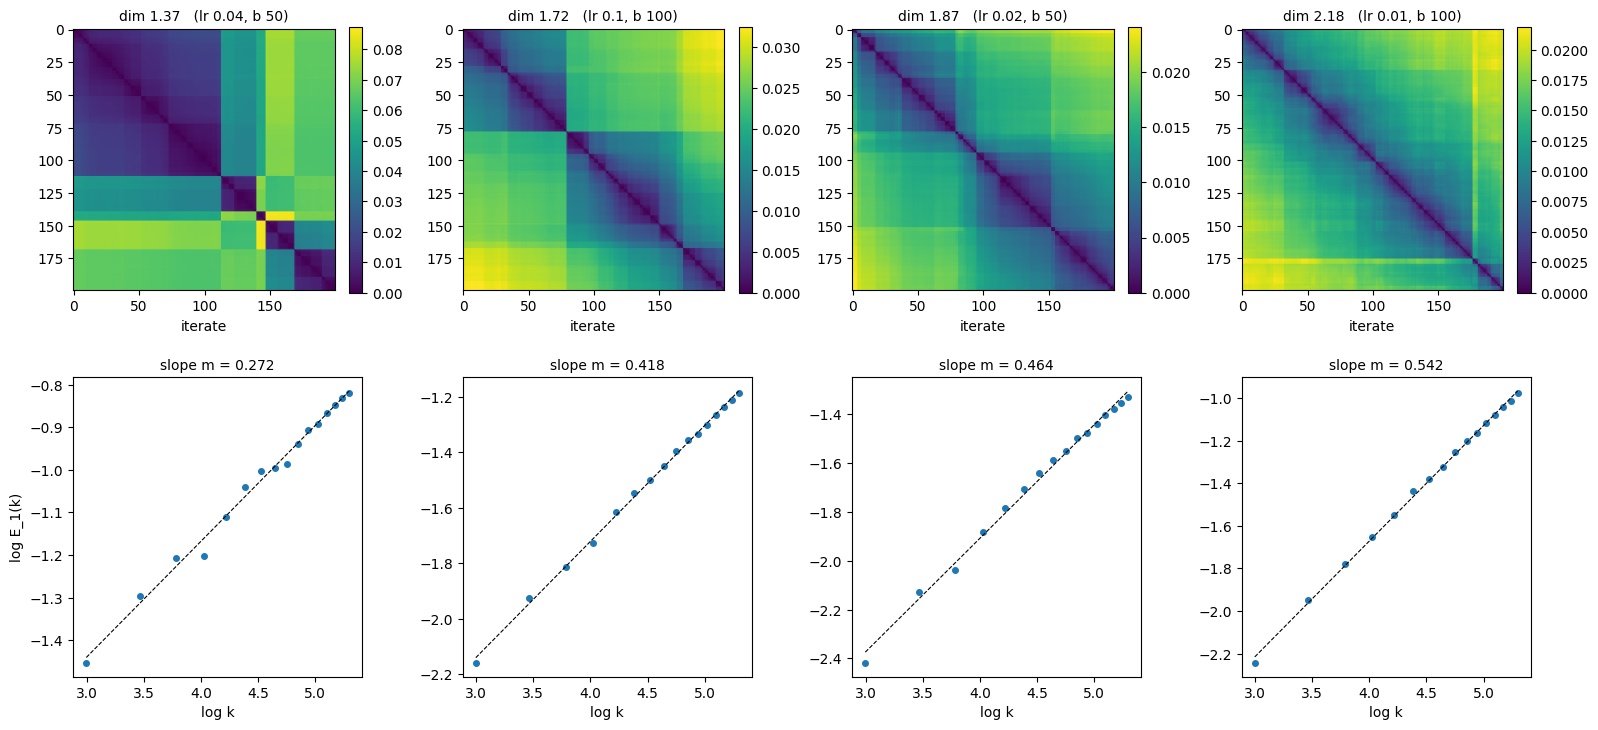

In [14]:
by_dim = sorted(ok, key=lambda r: r["dim"])
picks = [by_dim[i] for i in np.linspace(0, len(by_dim) - 1, 4).round().astype(int)]

fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for col, r in enumerate(picks):
    ax = axes[0, col]
    im = ax.imshow(r["D"], cmap="viridis")
    ax.set_title(f"dim {r['dim']:.2f}   (lr {r['lr']}, b {r['batch_size']})", fontsize=10)
    ax.set_xlabel("iterate")
    fig.colorbar(im, ax=ax, fraction=0.046)
    ax = axes[1, col]
    c = r["curve"]
    x = np.log(c["k"])
    ax.plot(x, c["log_E"], "o", ms=4)
    ax.plot(x, c["slope"] * x + c["intercept"], "k--", lw=0.8)
    ax.set_title(f"slope m = {c['slope']:.3f}", fontsize=10)
    ax.set_xlabel("log k")
axes[1, 0].set_ylabel("log E_1(k)")
plt.tight_layout()
plt.show()